In [1]:
import pandas as pd

ruta_archivo = r"C:\Users\aguig\Desktop\MASTER CEMP\base pulida.csv"

base_pulida = pd.read_csv(
    ruta_archivo,
    sep=";",
    encoding="latin1"
)

print(base_pulida.shape)
print(base_pulida.head())

(5110, 12)
      id Género  Edad Hipertensión Enfermedad cardíaca Casado    Empleo  \
0   9046  Varón  67.0           No                  Sí     Sí   Privado   
1  51676  Mujer  61.0           No                  No     Sí  Autónomo   
2  31112  Varón  80.0           No                  Sí     Sí   Privado   
3  60182  Mujer  49.0           No                  No     Sí   Privado   
4   1665  Mujer  79.0           Sí                  No     Sí  Autónomo   

  Residencia  Glucosa   IMC     Tabaco Ictus  
0     Urbana   228.69  36.6  Exfumador    Sí  
1      Rural   202.21   NaN      Nunca    Sí  
2      Rural   105.92  32.5      Nunca    Sí  
3     Urbana   171.23  34.4    Fumador    Sí  
4      Rural   174.12  24.0      Nunca    Sí  


In [2]:
print("Dimensiones:")
print(base_pulida.shape)

print("\nTipos de variables:")
print(base_pulida.dtypes)

print("\nValores perdidos:")
print(base_pulida.isna().sum())

Dimensiones:
(5110, 12)

Tipos de variables:
id                       int64
Género                  object
Edad                   float64
Hipertensión            object
Enfermedad cardíaca     object
Casado                  object
Empleo                  object
Residencia              object
Glucosa                float64
IMC                    float64
Tabaco                  object
Ictus                   object
dtype: object

Valores perdidos:
id                       0
Género                   0
Edad                     0
Hipertensión             0
Enfermedad cardíaca      0
Casado                   0
Empleo                   0
Residencia               0
Glucosa                  0
IMC                    201
Tabaco                   0
Ictus                    0
dtype: int64


In [3]:
variables_categoricas = [
    "Género",
    "Hipertensión",
    "Enfermedad cardíaca",
    "Casado",
    "Empleo",
    "Residencia",
    "Tabaco",
    "Ictus"
]

for var in variables_categoricas:

    print("\n" + "="*60)
    print(var)
    print("="*60)

    tabla = pd.DataFrame({
        "Frecuencia": base_pulida[var].value_counts(dropna=False),
        "Porcentaje (%)": round(
            base_pulida[var].value_counts(
                dropna=False,
                normalize=True
            ) * 100,
            3
        )
    })

    print(tabla)


Género
        Frecuencia  Porcentaje (%)
Género                            
Mujer         2994          58.591
Varón         2115          41.389
Other            1           0.020

Hipertensión
              Frecuencia  Porcentaje (%)
Hipertensión                            
No                  4612          90.254
Sí                   498           9.746

Enfermedad cardíaca
                     Frecuencia  Porcentaje (%)
Enfermedad cardíaca                            
No                         4834          94.599
Sí                          276           5.401

Casado
        Frecuencia  Porcentaje (%)
Casado                            
Sí            3353          65.616
No            1757          34.384

Empleo
          Frecuencia  Porcentaje (%)
Empleo                              
Privado         2925          57.241
Autónomo         819          16.027
Niño             687          13.444
Gobierno         657          12.857
Paro              22           0.431

Residencia

In [5]:
base_pulida = base_pulida[
    base_pulida["Género"] != "Other"
].copy()

print(base_pulida.shape)

print(base_pulida["Género"].value_counts(dropna=False))

(5109, 12)
Género
Mujer    2994
Varón    2115
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split
df_exp, df_val = train_test_split(
    base_pulida,
    test_size=0.30,
    random_state=123,
    stratify=base_pulida["Ictus"]
)
print(df_exp.shape)
print(df_val.shape)

(3576, 12)
(1533, 12)


In [8]:
mediana_imc = df_exp["IMC"].median()

df_exp["IMC"] = df_exp["IMC"].fillna(mediana_imc)
df_val["IMC"] = df_val["IMC"].fillna(mediana_imc)

In [9]:
print(df_exp["IMC"].isna().sum())
print(df_val["IMC"].isna().sum())

0
0


In [10]:
from scipy.stats import normaltest

for var in ["Edad", "Glucosa", "IMC"]:

    media = round(base_pulida[var].mean(), 2)
    mediana = round(base_pulida[var].median(), 2)

    stat, p = normaltest(base_pulida[var].dropna())

    print("\n" + "="*50)
    print(var)
    print("="*50)

    print("Media:", media)
    print("Mediana:", mediana)
    print("Estadístico:", round(stat, 3))
    print("p:", p)

    print(
    base_pulida[
        ["Edad", "Glucosa", "IMC"]
    ].describe()
)


Edad
Media: 43.23
Mediana: 45.0
Estadístico: 1119.928
p: 6.466817238449553e-244
              Edad      Glucosa         IMC
count  5109.000000  5109.000000  4908.00000
mean     43.229986   106.140399    28.89456
std      22.613575    45.285004     7.85432
min       0.080000    55.120000    10.30000
25%      25.000000    77.240000    23.50000
50%      45.000000    91.880000    28.10000
75%      61.000000   114.090000    33.10000
max      82.000000   271.740000    97.60000

Glucosa
Media: 106.14
Mediana: 91.88
Estadístico: 1329.332
p: 2.1840552435286905e-289
              Edad      Glucosa         IMC
count  5109.000000  5109.000000  4908.00000
mean     43.229986   106.140399    28.89456
std      22.613575    45.285004     7.85432
min       0.080000    55.120000    10.30000
25%      25.000000    77.240000    23.50000
50%      45.000000    91.880000    28.10000
75%      61.000000   114.090000    33.10000
max      82.000000   271.740000    97.60000

IMC
Media: 28.89
Mediana: 28.1
Estadíst

In [11]:
import pandas as pd

df_global = pd.concat([df_exp, df_val], ignore_index=True)

tabla1 = []

tabla1.append([
    "Edad, media ± DE",
    f"{df_global['Edad'].mean():.2f} ± {df_global['Edad'].std():.2f}",
    f"{df_exp['Edad'].mean():.2f} ± {df_exp['Edad'].std():.2f}",
    f"{df_val['Edad'].mean():.2f} ± {df_val['Edad'].std():.2f}"
])

tabla1.append([
    "IMC, mediana (RIC)",
    f"{df_global['IMC'].median():.2f} ({df_global['IMC'].quantile(0.25):.2f}-{df_global['IMC'].quantile(0.75):.2f})",
    f"{df_exp['IMC'].median():.2f} ({df_exp['IMC'].quantile(0.25):.2f}-{df_exp['IMC'].quantile(0.75):.2f})",
    f"{df_val['IMC'].median():.2f} ({df_val['IMC'].quantile(0.25):.2f}-{df_val['IMC'].quantile(0.75):.2f})"
])

tabla1.append([
    "Glucosa, mediana (RIC)",
    f"{df_global['Glucosa'].median():.2f} ({df_global['Glucosa'].quantile(0.25):.2f}-{df_global['Glucosa'].quantile(0.75):.2f})",
    f"{df_exp['Glucosa'].median():.2f} ({df_exp['Glucosa'].quantile(0.25):.2f}-{df_exp['Glucosa'].quantile(0.75):.2f})",
    f"{df_val['Glucosa'].median():.2f} ({df_val['Glucosa'].quantile(0.25):.2f}-{df_val['Glucosa'].quantile(0.75):.2f})"
])

variables = {
    "Género": ["Mujer", "Varón"],
    "Hipertensión": ["No", "Sí"],
    "Enfermedad cardíaca": ["No", "Sí"],
    "Casado": ["No", "Sí"],
    "Empleo": ["Privado", "Autónomo", "Gobierno", "Niño", "Paro"],
    "Residencia": ["Urbana", "Rural"],
    "Tabaco": ["Exfumador", "Nunca", "Fumador", "Desconocido"],
    "Ictus": ["No", "Sí"]
}

for variable, categorias in variables.items():

    tabla1.append([variable, "", "", ""])

    for categoria in categorias:

        n_global = (df_global[variable] == categoria).sum()
        n_exp = (df_exp[variable] == categoria).sum()
        n_val = (df_val[variable] == categoria).sum()

        tabla1.append([
            categoria,
            f"{n_global} ({100*n_global/len(df_global):.1f}%)",
            f"{n_exp} ({100*n_exp/len(df_exp):.1f}%)",
            f"{n_val} ({100*n_val/len(df_val):.1f}%)"
        ])

tabla1 = pd.DataFrame(
    tabla1,
    columns=[
        "Variable",
        "Global (n=5109)",
        "Exploratoria (n=3576)",
        "Confirmación (n=1533)"
    ]
)

pd.set_option("display.max_rows", None)

print(tabla1.to_string(index=False))

              Variable      Global (n=5109) Exploratoria (n=3576) Confirmación (n=1533)
      Edad, media ± DE        43.23 ± 22.61         42.76 ± 22.67         44.32 ± 22.45
    IMC, mediana (RIC)  28.10 (23.80-32.80)   28.10 (23.70-32.80)   28.10 (24.00-32.70)
Glucosa, mediana (RIC) 91.88 (77.24-114.09)  92.12 (77.29-113.70)  91.34 (77.08-114.82)
                Género                                                                 
                 Mujer         2994 (58.6%)          2099 (58.7%)           895 (58.4%)
                 Varón         2115 (41.4%)          1477 (41.3%)           638 (41.6%)
          Hipertensión                                                                 
                    No         4611 (90.3%)          3229 (90.3%)          1382 (90.2%)
                    Sí           498 (9.7%)            347 (9.7%)            151 (9.8%)
   Enfermedad cardíaca                                                                 
                    No         4

In [12]:
y_exp = df_exp["Ictus"].map({"No": 0, "Sí": 1})
y_val = df_val["Ictus"].map({"No": 0, "Sí": 1})

X_exp = df_exp.drop(columns=["Ictus"])
X_val = df_val.drop(columns=["Ictus"])

X_exp = pd.get_dummies(
    X_exp,
    drop_first=True
)

X_val = pd.get_dummies(
    X_val,
    drop_first=True
)

X_exp = X_exp.drop(columns=["id"])
X_val = X_val.drop(columns=["id"])

X_exp, X_val = X_exp.align(
    X_val,
    join="left",
    axis=1,
    fill_value=0
)

print(X_exp.shape)
print(X_val.shape)

(3576, 15)
(1533, 15)


In [13]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_exp_sm, y_exp_sm = smote.fit_resample(
    X_exp,
    y_exp
)

print(y_exp_sm.value_counts())

Ictus
1    3402
0    3402
Name: count, dtype: int64


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    f1_score,
    confusion_matrix
)
from xgboost import XGBClassifier
import pandas as pd

lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=1.0,
    eval_metric="logloss",
    random_state=123
)

modelos = {
    "Regresión logística": lr,
    "Random Forest": rf,
    "XGBoost": xgb
}

resultados = []

for nombre, modelo in modelos.items():

    modelo.fit(X_exp_sm, y_exp_sm)

    y_pred = modelo.predict(X_val)
    y_prob = modelo.predict_proba(X_val)[:,1]

    auc = roc_auc_score(y_val, y_prob)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred
    ).ravel()

    sensibilidad = tp/(tp+fn)
    especificidad = tn/(tn+fp)

    precision = precision_score(
        y_val,
        y_pred
    )

    f1 = f1_score(
        y_val,
        y_pred
    )

    resultados.append({
        "Modelo": nombre,
        "AUC": round(auc,3),
        "Sensibilidad": round(sensibilidad,3),
        "Especificidad": round(especificidad,3),
        "Precisión": round(precision,3),
        "F1": round(f1,3)
    })

df_metricas = pd.DataFrame(resultados)

print(df_metricas)

                Modelo    AUC  Sensibilidad  Especificidad  Precisión     F1
0  Regresión logística  0.756         0.400          0.862      0.130  0.196
1        Random Forest  0.792         0.440          0.840      0.124  0.193
2              XGBoost  0.759         0.187          0.958      0.187  0.187


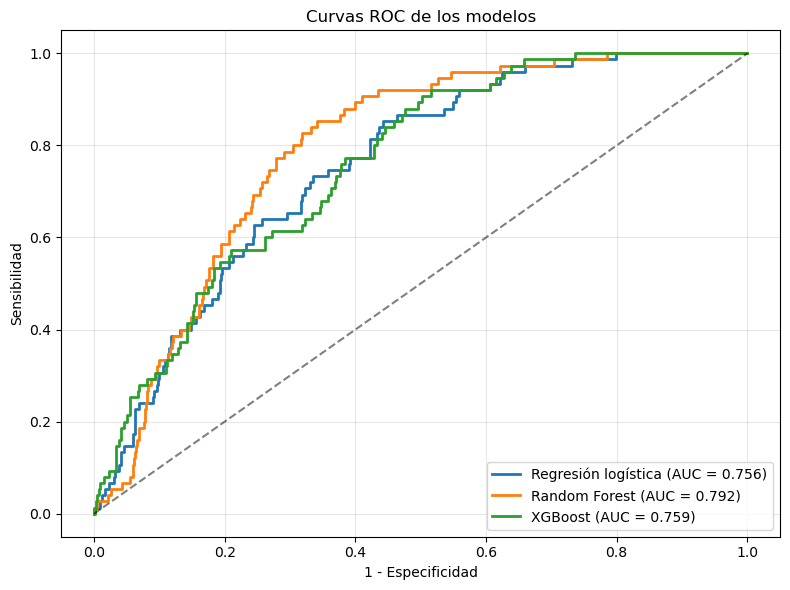

In [17]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

prob_lr = lr.predict_proba(X_val)[:,1]
prob_rf = rf.predict_proba(X_val)[:,1]
prob_xgb = xgb.predict_proba(X_val)[:,1]

fpr_lr, tpr_lr, _ = roc_curve(y_val, prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_val, prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, prob_xgb)

auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)
auc_xgb = auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(8,6))

plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f"Regresión logística (AUC = {auc_lr:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot([0,1],[0,1],"k--",alpha=0.5)

plt.xlabel("1 - Especificidad")
plt.ylabel("Sensibilidad")
plt.title("Curvas ROC de los modelos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

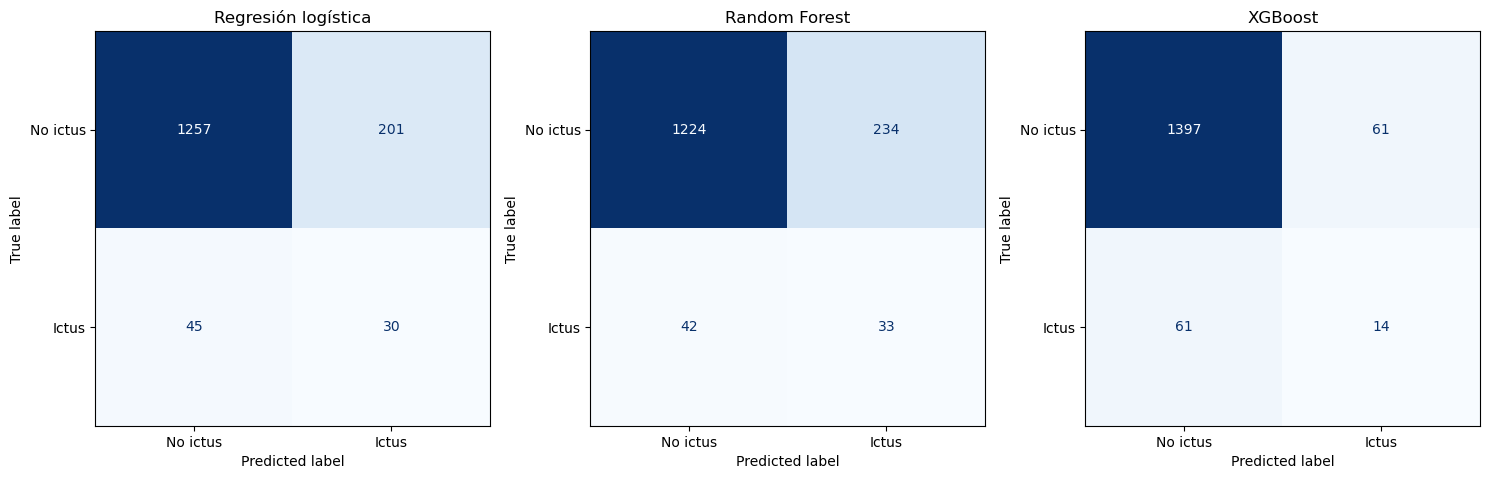

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_lr_05 = (prob_lr >= 0.5).astype(int)
pred_rf_05 = (prob_rf >= 0.5).astype(int)
pred_xgb_05 = (prob_xgb >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))


ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_lr_05),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("Regresión logística")


ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_rf_05),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("Random Forest")


ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_xgb_05),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[2],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[2].set_title("XGBoost")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import roc_curve
import numpy as np

for nombre, prob in {
    "LR": prob_lr,
    "RF": prob_rf,
    "XGB": prob_xgb
}.items():

    fpr, tpr, thresholds = roc_curve(y_val, prob)

    youden = tpr - fpr

    idx = np.argmax(youden)

    print(
        nombre,
        "umbral =",
        round(thresholds[idx], 6)
    )

LR umbral = 0.081583
RF umbral = 0.312698
XGB umbral = 0.011246


In [21]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    f1_score
)

import numpy as np
import pandas as pd

resultados_youden = []

for nombre, prob in [
    ("Regresión logística", prob_lr),
    ("Random Forest", prob_rf),
    ("XGBoost", prob_xgb)
]:

    fpr, tpr, thresholds = roc_curve(y_val, prob)

    youden = tpr - fpr

    idx = np.argmax(youden)

    umbral = thresholds[idx]

    pred = (prob >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        pred
    ).ravel()

    sensibilidad = tp / (tp + fn)

    especificidad = tn / (tn + fp)

    precision = precision_score(
        y_val,
        pred
    )

    f1 = f1_score(
        y_val,
        pred
    )

    auc = roc_auc_score(
        y_val,
        prob
    )

    resultados_youden.append({
        "Modelo": nombre,
        "Punto de corte (Youden)": round(umbral, 3),
        "AUC": round(auc, 3),
        "Sensibilidad": round(sensibilidad, 3),
        "Especificidad": round(especificidad, 3),
        "Precisión": round(precision, 3),
        "F1": round(f1, 3)
    })

tabla_youden = pd.DataFrame(resultados_youden)

print(tabla_youden)

                Modelo  Punto de corte (Youden)    AUC  Sensibilidad  \
0  Regresión logística                    0.082  0.756         0.853   
1        Random Forest                    0.313  0.792         0.853   
2              XGBoost                    0.011  0.759         0.907   

   Especificidad  Precisión     F1  
0          0.558      0.090  0.163  
1          0.659      0.114  0.201  
2          0.499      0.085  0.156  


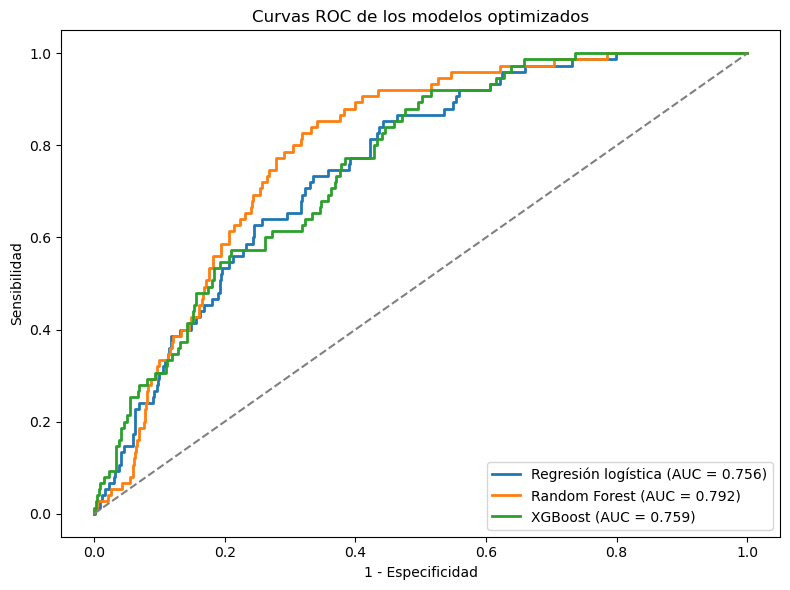

In [22]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for nombre, prob in [
    ("Regresión logística", prob_lr),
    ("Random Forest", prob_rf),
    ("XGBoost", prob_xgb)
]:

    fpr, tpr, _ = roc_curve(y_val, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {roc_auc:.3f})"
    )

plt.plot([0,1],[0,1], "--", color="grey")

plt.xlabel("1 - Especificidad")
plt.ylabel("Sensibilidad")
plt.title("Curvas ROC de los modelos optimizados")

plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

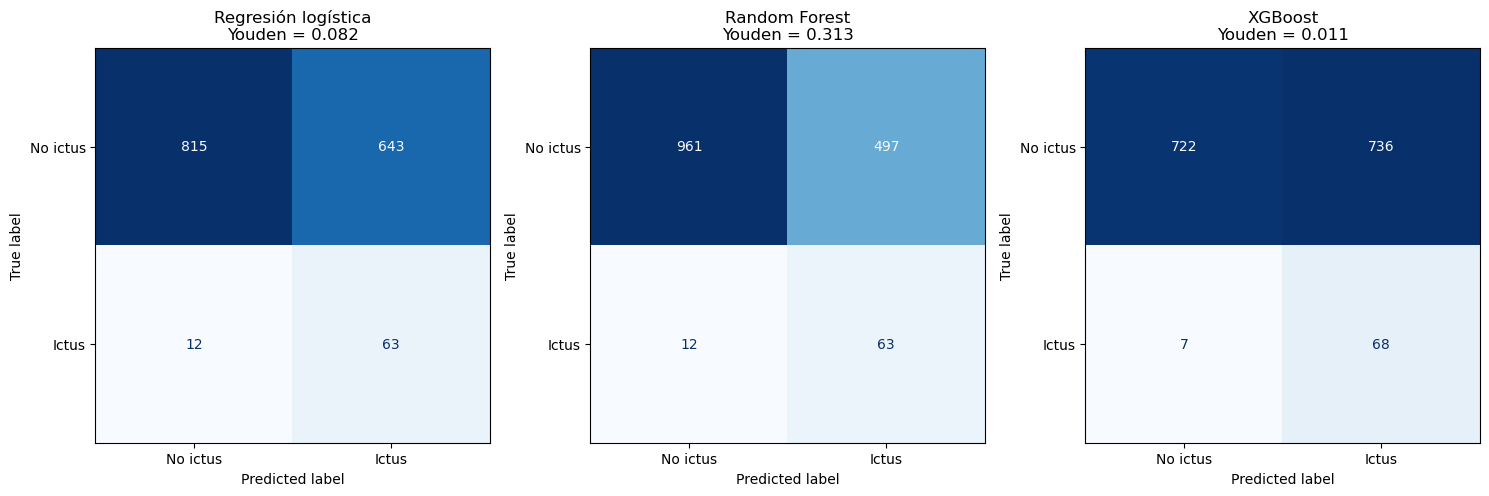

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

thr_lr = tabla_youden.loc[
    tabla_youden["Modelo"]=="Regresión logística",
    "Punto de corte (Youden)"
].iloc[0]

thr_rf = tabla_youden.loc[
    tabla_youden["Modelo"]=="Random Forest",
    "Punto de corte (Youden)"
].iloc[0]

thr_xgb = tabla_youden.loc[
    tabla_youden["Modelo"]=="XGBoost",
    "Punto de corte (Youden)"
].iloc[0]

pred_lr = (prob_lr >= thr_lr).astype(int)
pred_rf = (prob_rf >= thr_rf).astype(int)
pred_xgb = (prob_xgb >= thr_xgb).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15,5))

ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_lr),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title(
    f"Regresión logística\nYouden = {thr_lr:.3f}"
)

ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_rf),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title(
    f"Random Forest\nYouden = {thr_rf:.3f}"
)

ConfusionMatrixDisplay(
    confusion_matrix(y_val, pred_xgb),
    display_labels=["No ictus", "Ictus"]
).plot(
    ax=axes[2],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[2].set_title(
    f"XGBoost\nYouden = {thr_xgb:.3f}"
)

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd

importance_df = pd.DataFrame({
    "Variable": X_exp.columns,
    "Importancia": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importancia",
    ascending=False
)

print(importance_df)

                  Variable  Importancia
0                     Edad     0.351548
4          Hipertensión_Sí     0.148556
6                Casado_Sí     0.091316
5   Enfermedad cardíaca_Sí     0.068360
12        Tabaco_Exfumador     0.057748
11       Residencia_Urbana     0.055609
1                  Glucosa     0.052716
10          Empleo_Privado     0.051267
2                      IMC     0.034903
13          Tabaco_Fumador     0.025777
14            Tabaco_Nunca     0.020589
3             Género_Varón     0.019263
7          Empleo_Gobierno     0.012244
8              Empleo_Niño     0.010093
9              Empleo_Paro     0.000013


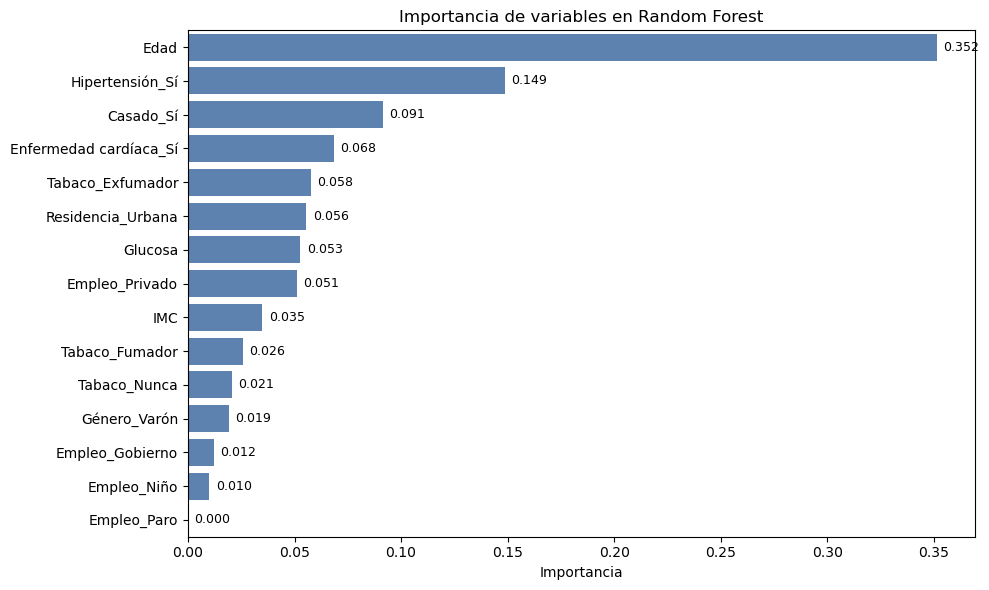

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df,
    x="Importancia",
    y="Variable",
    color="#4F81BD"
)

plt.title(
    "Importancia de variables en Random Forest"
)

for i, v in enumerate(importance_df["Importancia"]):
    plt.text(
        v + 0.003,
        i,
        f"{v:.3f}",
        va="center",
        fontsize=9
    )

plt.xlabel("Importancia")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [1]:
import os
print(os.getcwd())

C:\Users\aguig
